In [2]:
# SETUP
# Import the local `src` package (run the notebook from the repository root).
import src as mk

In [3]:
# STEP 1 - DOWNLOAD DAILY MAXIMUM TEMPERATURE FOR ALL STUDY AREAS
# T2M_MAX (daily, 1981-2025, NASA POWER) for every location of the four study areas: Kech,
# Gwadar (labelled 'Gawadar' in the code), Panjgur and Tump. The coordinates are the same as
# in the per-district notebooks. One MultiDataFrame per area; `m_data` collects the
# area-level series. Requires internet access.
# Will hold one averaged series per study area.
m_data = mk.MultiDataFrame()

# Kech
# Container for the locations of the first area (Kech).
k_data = mk.MultiDataFrame()

# d_1 ... d_4: area names used as labels.
d_1 = "Kech"

# Only daily maximum temperature is needed for the heatwave index.
k_data.set_default_parameters("T2M_MAX")

# One call per location: name = label, lat/lon = decimal degrees (WGS84). Same pattern for
# every area below.
k_data.fetch_and_add(name="Turbat",lat=26.004168,lon=63.060555)
k_data.fetch_and_add(name="Dasht",lat=25.709777,lon=62.622079)
k_data.fetch_and_add(name="Buleda",lat=26.3985,lon=62.9206)
k_data.fetch_and_add(name="Hoshab",lat=26.0155, lon=63.8818)
k_data.fetch_and_add(name="Balnigor",lat=25.832619, lon=62.261213)




# Gawadar
g_data = mk.MultiDataFrame()

d_2 = "Gawadar"

g_data.set_default_parameters("T2M_MAX")

g_data.fetch_and_add(name="Gwadar",lat=25.12648,lon=62.3225)
g_data.fetch_and_add(name="Jiwani",lat=25.0504,lon=61.7420)
g_data.fetch_and_add(name="Pasni",lat=25.2624,lon=63.4713)
g_data.fetch_and_add(name="Ormara",lat=25.2144, lon=64.6333)
g_data.fetch_and_add(name="Suntar",lat=25.5022, lon=61.9817)


#Panjgur
p_data = mk.MultiDataFrame()

d_3 = "Panjgur"

p_data.set_default_parameters("T2M_MAX")

p_data.fetch_and_add(name="Panjgur",lat=26.9683,lon=64.1014)
p_data.fetch_and_add(name="Parome",lat=26.5670,lon=63.3850)
p_data.fetch_and_add(name="Gowargo",lat=26.7830,lon=64.2670)
p_data.fetch_and_add(name="Gichk",lat=26.6670, lon=64.5170)

#Tump
t_data = mk.MultiDataFrame()

d_4 = "Tump"

t_data.set_default_parameters("T2M_MAX")

t_data.fetch_and_add(name="Tump",lat=26.0969,lon=62.3654)
t_data.fetch_and_add(name="Mand",lat=26.37,lon=61.75)




INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 26.004168 | Lon: 63.060555 | Period: 1981-01-01 → 2025-12-31
INFO:mahgir.weather_api.nasa_power:Data fetched successfully.
INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 25.709777 | Lon: 62.622079 | Period: 1981-01-01 → 2025-12-31
INFO:mahgir.weather_api.nasa_power:Data fetched successfully.
INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 26.398500 | Lon: 62.920600 | Period: 1981-01-01 → 2025-12-31
INFO:mahgir.weather_api.nasa_power:Data fetched successfully.
INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 26.015500 | Lon: 63.881800 | Period: 1981-01-01 → 2025-12-31
INFO:mahgir.weather_api.nasa_power:Data fetched successfully.
INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 25.832619 | Lon: 62.261213 | Period: 1981-01-01 → 2025-12-31
INFO:mahgir.weather_api.nasa_power:Data fetched successfully.
INFO:mahgir.weather_api.nasa_power:Fetching data | Lat: 25.126480 | Lon: 62.322500 | Period: 1981-01-01 →

In [4]:
# Copies of the raw downloads (the originals stay untouched).
k_data1 = k_data.copy()
g_data1 = g_data.copy()
p_data1 = p_data.copy()
t_data1 = t_data.copy()

In [5]:
# STEP 2 - AREA-LEVEL SERIES
# Average the location series of each area: element-wise arithmetic mean with equal weights
# (5 locations for Kech and Gwadar, 4 for Panjgur, 2 for Tump). A date is NaN in the average
# if any location is missing on that date. The averages are stored in `m_data` in the order
# Kech (0), Gawadar (1), Panjgur (2), Tump (3).
#kech
# Kech: mean of its 5 locations.
temp = mk.DataFrame((k_data1[0]+k_data1[1]+k_data1[2]+k_data1[3]+k_data1[4])/5)
# Register the averaged series under the area name.
m_data.add_data(temp,d_1)

#gawadar
# Gawadar: mean of its 5 locations.
temp = mk.DataFrame((g_data1[0]+g_data1[1]+g_data1[2]+g_data1[3]+g_data1[4])/5)
m_data.add_data(temp,d_2)

#panj
# Panjgur: mean of its 4 locations.
temp = mk.DataFrame((p_data1[0]+p_data1[1]+p_data1[2]+p_data1[3])/4)
m_data.add_data(temp,d_3)

#tump
# Tump: mean of its 2 locations.
temp = mk.DataFrame((t_data1[0]+t_data1[1])/2)
m_data.add_data(temp,d_4)


In [7]:
# Copy of the area-level series.
data5 = m_data.copy()

In [8]:
# Remove 29 February so that every year has 365 days (required by the heatwave function).
for i in data5.keys():
    # In-place removal of 29 February for each area series.
    data5[i].drop_leap_days(inplace = True)

In [9]:
# STEP 3 - HEATWAVE DAYS
# Replace each area-level daily series by its annual number of heatwave days (1981-2025):
# runs of at least 3 consecutive days whose T2M_MAX anomaly exceeds the day-of-year 90th
# percentile of the 1981-2010 baseline.
for i in data5.keys():
    # Output: DataFrame indexed by year with the column Total_Heatwave_Days.
    data5[i] = mk.DataFrame(mk.heatwave(data5[i]))

In [10]:
# Copy of the heatwave-day counts for plotting.
data6 = data5.copy()

Kech  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(1.7763568394002505e-15), z=np.float64(7.963692259301092), Tau=np.float64(0.3323232323232323), s=np.float64(329.0), var_s=np.float64(1696.362834327541), slope=np.float64(0.6869328493647913), intercept=np.float64(14.887477313974593))
Gawadar  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(7.658533744958618e-07), z=np.float64(4.943873681798785), Tau=np.float64(0.31212121212121213), s=np.float64(309.0), var_s=np.float64(3881.2060652878977), slope=np.float64(0.5303308823529411), intercept=np.float64(16.332720588235297))
Panjgur  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(9.776161761366986), Tau=np.float64(0.396969696969697), s=np.float64(393.0), var_s=np.float64(1607.8124082974834), slope=np.float64(0.9424342105263157), intercept=np.float64(8.266447368421055))
Tump  =  Modified_Ma

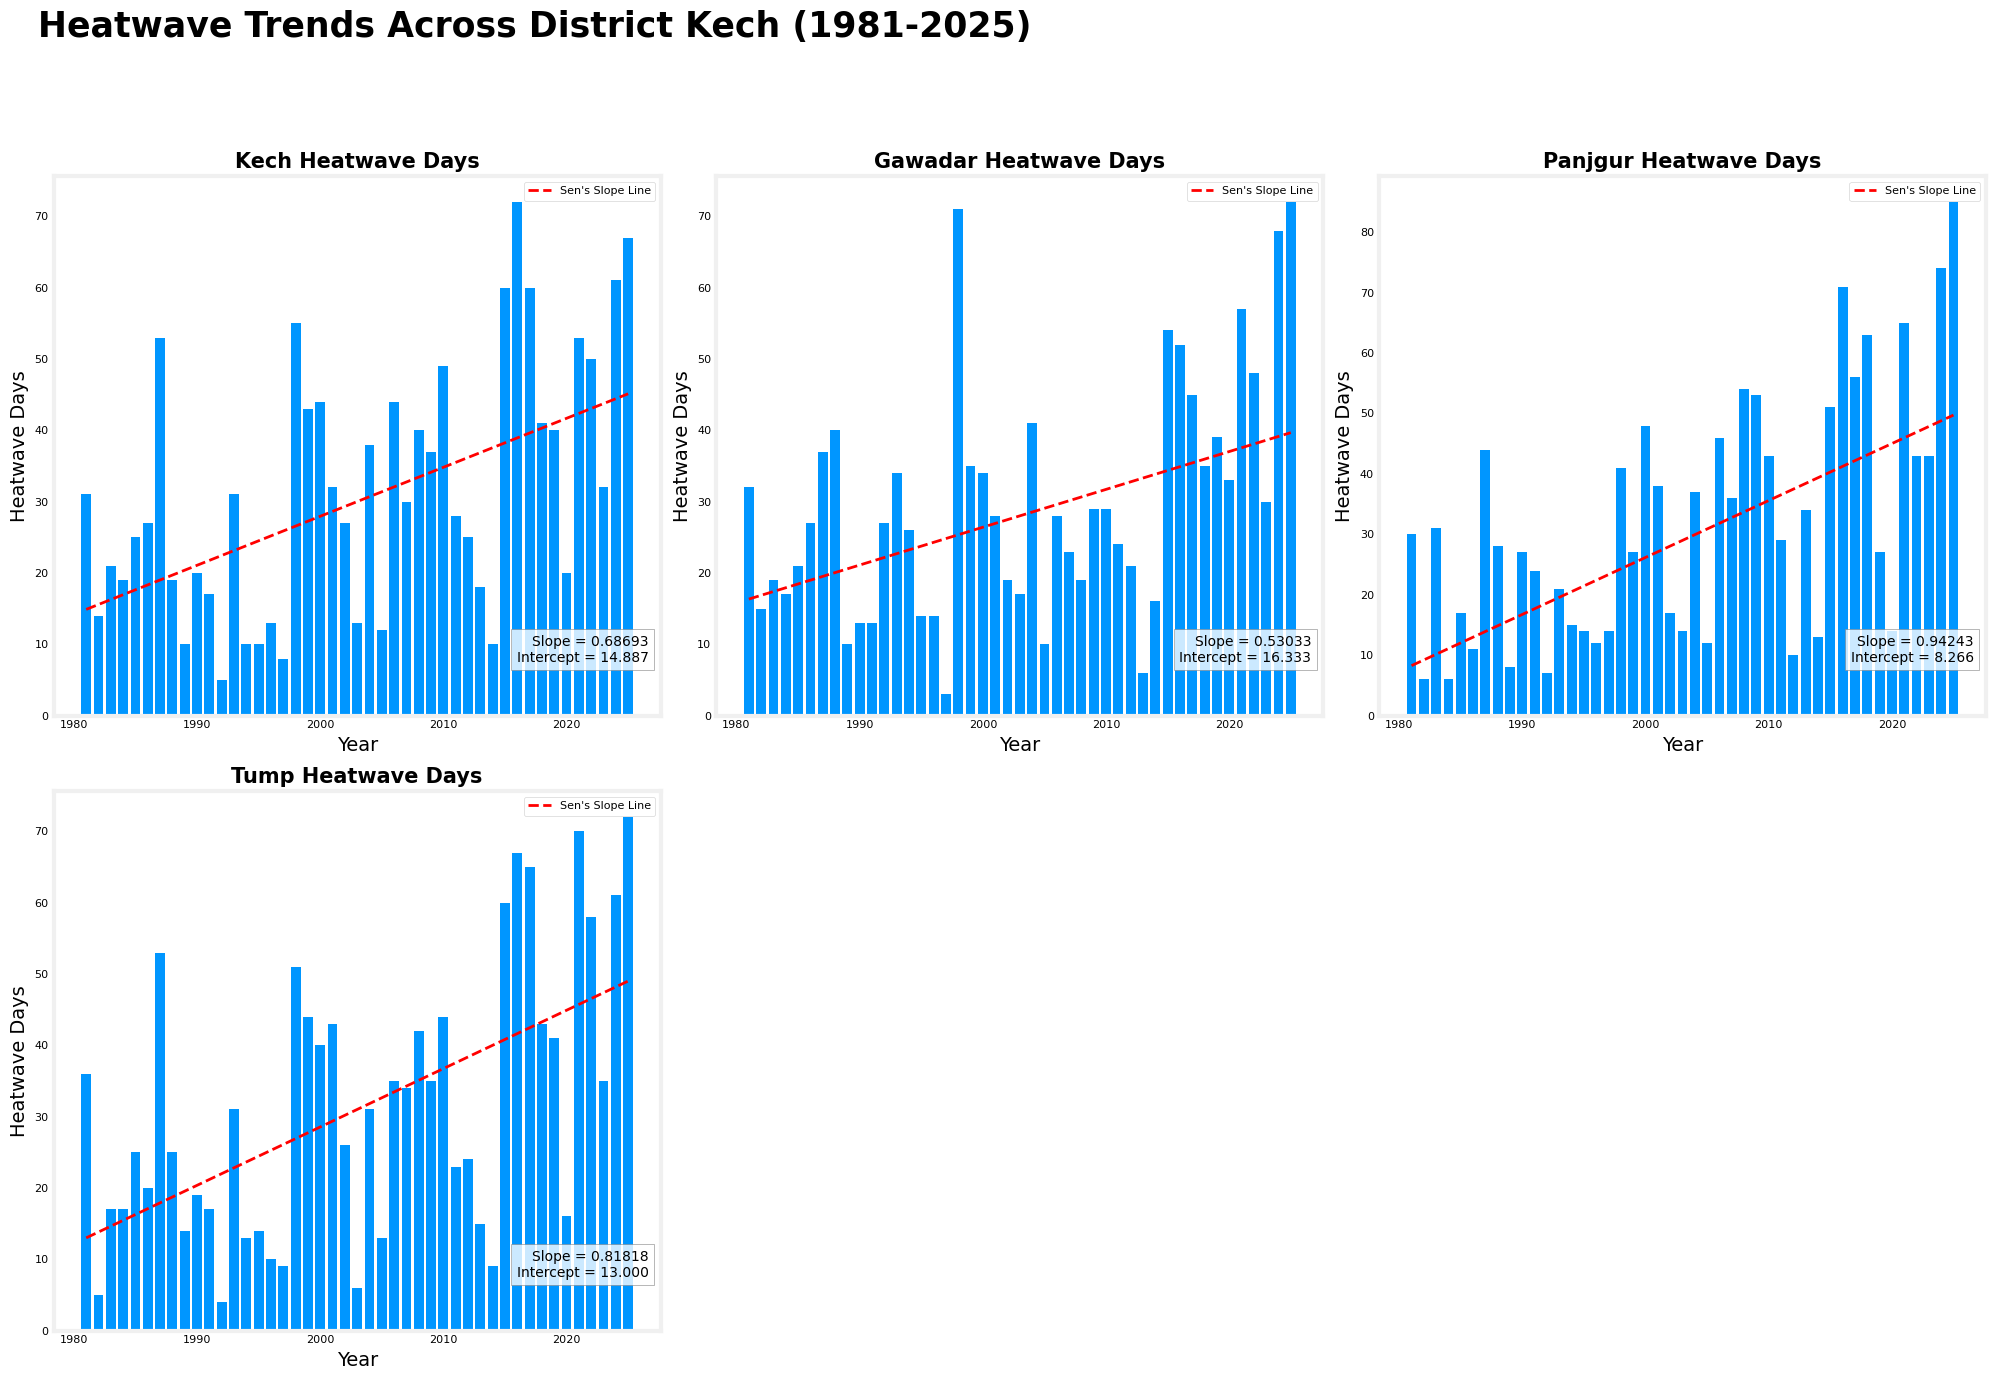

In [ ]:
# FIGURE - HEATWAVE-DAY TRENDS ACROSS THE MAKRAN DIVISION
# Bar chart of annual heatwave days per area with Modified Mann-Kendall / Sen's slope trend
# line. The figure is also saved as combined_figure_3.pdf.
import matplotlib.pyplot as plt

# Apply the project's Matplotlib style sheet (relative path, so run the notebook from the
# repository root).
plt.style.use("./deeplearning.mplstyle")

# Grid of panels, one per study area (the two unused panels are removed below).
fig, ax = plt.subplots(2, 3, figsize=(20, 14))
# Flat list of Axes: panel i belongs to area key i.
ax_plots = [
    ax[0,0],ax[0,1],ax[0,2],
    ax[1,0],ax[1,1],ax[1,2]
]


# Loop over the four study areas.
for i in data6.keys():
    # Bar chart of annual heatwave days for area i, then the trend line.
    # Fit and draw the trend line with the Modified Mann-Kendall test (Yue-Wang variance
    # correction for autocorrelation, via pymannkendall); the line is Sen's slope. The
    # returned object holds trend, h, p, z, Tau, s, var_s, slope and intercept.
    trend = data6[i].chart("Total_Heatwave_Days",ct="bar",ax = ax_plots[i]).mann_kendall("yue_wang_modification_test",color="red",linestyle="--",linewidth=2,label="Sen's Slope Line")
    
    # Print the full test result for this area.
    print(data6.meta_data[i]["name"]," = ",trend)
    # Visual separator between areas in the printed output.
    print(200*"==")
    
    ax_plots[i].set_title(f"{data6.meta_data[i]["name"]} Heatwave Days", fontsize=15, fontweight="bold")
    ax_plots[i].legend()
    ax_plots[i].set_xlabel("Year", fontsize=14)
    ax_plots[i].set_ylabel("Heatwave Days", fontsize=14)


    # Annotate the panel with the fitted slope and intercept.
    ax_plots[i].text(
        0.98, 0.15,
        f"Slope = {trend.slope:.5f}\nIntercept = {trend.intercept:.3f}",
        transform=ax_plots[i].transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
    )

# Overall figure title.
fig.suptitle(
    f"Heatwave Trends Across Makran Division",
    x=0.02,          # left aligned
    ha="left",
    fontsize=25,
    fontweight="bold"
)

# fig.text(
#     0.02, 0.90,
#     "Annual heatwave day counts with linear trend lines across District Kech (1981-2025)",
#     ha="left",
#     fontsize=15,
#     color="dimkray"
# )

# Delete the unused panel(s) of the grid.
ax_plots[4].remove()
ax_plots[5].remove()
# Leave room at the top for the overall title.
plt.tight_layout(rect=[0, 0, 1, 0.92])
# Save the figure as a vector PDF in the current working directory before displaying it.
plt.savefig(f"combined_figure_3.pdf")
plt.show()